# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [8]:

print("Dimensiones de los datasets:")
print("Planes:", plans.shape)
print("Clientes:", users.shape)
print("Uso:", usage.shape)

print("\nInformación de planes:")
plans.info()

print("\nInformación de clientes:")
users.info()

print("\nInformación de uso:")
usage.info()

Dimensiones de los datasets:
Planes: (2, 8)
Clientes: (4000, 8)
Uso: (40000, 6)

Información de planes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes

Información de clientes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int6

In [9]:
print("Valores faltantes en plans:")
display(plans.isna().sum())

print("Valores faltantes en users:")
display(users.isna().sum())

print("Valores faltantes en usage:")
display(usage.isna().sum())

Valores faltantes en plans:


plan_name            0
messages_included    0
gb_per_month         0
minutes_included     0
usd_monthly_pay      0
usd_per_gb           0
usd_per_message      0
usd_per_minute       0
dtype: int64

Valores faltantes en users:


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Valores faltantes en usage:


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

In [10]:
print("Duplicados exactos en plans:", plans.duplicated().sum())
print("Duplicados exactos en users:", users.duplicated().sum())
print("Duplicados exactos en usage:", usage.duplicated().sum())

print("\nIDs duplicados en users:", users['user_id'].duplicated().sum())
print("IDs duplicados en plans:", plans['plan_name'].duplicated().sum())

Duplicados exactos en plans: 0
Duplicados exactos en users: 0
Duplicados exactos en usage: 0

IDs duplicados en users: 0
IDs duplicados en plans: 0


In [11]:
print("Estadísticas de plans:")
display(plans.describe())

print("Estadísticas de users:")
display(users.describe())

print("Estadísticas de usage:")
display(usage.describe())

Estadísticas de plans:


,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
count,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
mean,300.000000,12.500000,350.000000,18.500000,1.100000,0.065000,0.085000
std,282.842712,10.606602,353.553391,9.192388,0.141421,0.021213,0.021213
min,100.000000,5.000000,100.000000,12.000000,1.000000,0.050000,0.070000
25%,200.000000,8.750000,225.000000,15.250000,1.050000,0.057500,0.077500
50%,300.000000,12.500000,350.000000,18.500000,1.100000,0.065000,0.085000
75%,400.000000,16.250000,475.000000,21.750000,1.150000,0.072500,0.092500
max,500.000000,20.000000,600.000000,25.000000,1.200000,0.080000,0.100000


Estadísticas de users:


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


Estadísticas de usage:


,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [12]:
# revisar el número de filas y columnas de cada dataset
print("plans:", plans.shape)
print("users:", users.shape)
print("usage:", usage.shape)

plans: (2, 8)
users: (4000, 8)
usage: (40000, 6)


In [13]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [14]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [15]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [16]:
# cantidad de nulos para users
print("Cantidad de valores nulos:")
print(users.isna().sum())

print("\nProporción de valores nulos:")
print(users.isna().mean() * 100)

Cantidad de valores nulos:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos:
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [17]:
# cantidad de nulos para usage
print("Cantidad de valores nulos:")
print(usage.isna().sum())

print("\nProporción de valores nulos:")
print(usage.isna().mean() * 100)

Cantidad de valores nulos:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos:
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
- ### Diagnóstico de valores nulos

- **`users.city`:** 469 valores nulos (11.725%). Investigar si se pueden recuperar a partir de otra fuente; si no, conservarlos como desconocidos para evitar eliminar clientes.
- **`users.churn_date`:** 3,534 valores nulos (88.35%). Verificar si representan clientes que siguen activos. Si es así, conservar los nulos, ya que contienen información sobre el estado del cliente.
- **`usage.date`:** 50 valores nulos (0.125%). Investigar si las fechas se pueden recuperar; de lo contrario, conservar los registros si son útiles para otros análisis y excluirlos de los análisis que requieran fecha.
- **`usage.duration`:** 22,076 valores nulos (55.19%). Investigar la relación con el tipo de actividad. No imputar ni eliminar hasta determinar por qué faltan los valores.
- **`usage.length`:** 17,896 valores nulos (44.74%). Revisar si los valores ausentes corresponden a llamadas u otros tipos de actividad. Definir el tratamiento según su significado.
- **`plans`:** no presenta valores nulos. No requiere tratamiento por valores ausentes en esta etapa.

**Conclusión:** Los valores nulos deben tratarse según su significado y proporción. Antes de imputar o eliminar datos, se deben comprobar las reglas del negocio y la relación entre las columnas.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [18]:
# explorar columnas numéricas de users
display(users[['user_id', 'age']].describe())

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `user_id` identifica a los clientes. En la exploración inicial presenta 4,000 valores no nulos. Se deben revisar los mínimos, máximos y posibles duplicados para confirmar la consistencia de los identificadores.
- - La columna `age` ...
- La columna `age` contiene un valor mínimo de -999, que es incompatible con una edad real y podría ser un valor centinela. Se debe identificar cuántos registros lo contienen antes de convertirlo en valor ausente o corregirlo.

In [19]:
# explorar columnas numéricas de usage
display(usage[['id', 'user_id', 'duration', 'length']].describe())

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...
Las columnas `id` y `user_id` funcionan como identificadores. En `duration` y `length` se deben revisar los valores mínimos y máximos para detectar posibles valores negativos o extremos. La interpretación debe considerar el tipo de actividad y los valores ausentes identificados previamente.

In [20]:
columnas_user = ['city', 'plan']

for columna in columnas_user:
    print(f"\nValores únicos de {columna}:")
    print(users[columna].value_counts(dropna=False))


Valores únicos de city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos de plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` ...
- La columna `plan` ...
- La columna `city` presenta valores ausentes, por lo que se deben revisar las categorías y su frecuencia. En `plan`, se deben verificar los nombres únicos y confirmar que coincidan con los planes disponibles en el catálogo.

In [21]:
# explorar columna categórica de usage
print(usage['type'].value_counts(dropna=False))

text    22092
call    17908
Name: type, dtype: int64


- La columna `type` ...
La columna `type` permite identificar las categorías de actividad registradas. Se deben comprobar sus valores únicos y frecuencias para detectar categorías inesperadas y comprender mejor los valores ausentes en `duration` y `length`.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
- ### Diagnóstico de valores inválidos o sentinels

- **`users.age`:** Se identificó un valor mínimo de -999, que no corresponde a una edad válida y podría ser un valor centinela. Se recomienda contar los registros afectados y convertir ese valor en ausente (`NaN`) antes de analizar las edades.
- **`users.user_id`:** Los identificadores deben ser únicos y positivos. Se recomienda verificar sus rangos y posibles duplicados; no se deben modificar si son válidos.
- **`usage.id` y `usage.user_id`:** Se recomienda verificar la unicidad de los identificadores de actividad y que los identificadores de usuario correspondan a clientes existentes.
- **`usage.duration` y `usage.length`:** Se deben revisar los valores mínimos y máximos para detectar números negativos o extremos. Antes de corregirlos, es necesario considerar el tipo de actividad y los valores ausentes.
- **Columnas categóricas (`users.city`, `users.plan` y `usage.type`):** Se deben revisar los valores únicos para identificar categorías inesperadas, errores de escritura o valores faltantes. Los planes deben coincidir con el catálogo disponible.

**Acción recomendada:** Investigar las anomalías, documentar las decisiones de limpieza y conservar los registros válidos. No eliminar datos ni sustituir valores sin una justificación basada en el contexto del negocio.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [22]:
# Convertir a fecha la columna reg_date de users
users['reg_date'] = pd.to_datetime(
    users['reg_date'],
    errors='coerce'
)

In [23]:
# Convertir a fecha la columna date de usage
usage['date'] = pd.to_datetime(
    usage['date'],
    errors='coerce'
)

In [25]:
# Revisar los años presentes en reg_date de users
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.
Se revisará la distribución de años de `reg_date` para identificar registros fuera del periodo esperado, que termina en 2024. Las fechas inválidas se convertirán en valores ausentes y deberán investigarse antes de decidir su tratamiento.

In [26]:
# Revisar los años presentes en date de usage
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())

2024.0    39950
NaN          50
Name: date, dtype: int64


In [27]:
# Revisar fechas fuera del periodo esperado: hasta 2024
print("Registros con reg_date posterior a 2024:")
display(users[users['reg_date'] > '2024-12-31'])

print("Registros con date posterior a 2024:")
display(usage[usage['date'] > '2024-12-31'])

print("Fechas de registro anteriores a 1900:")
display(users[users['reg_date'] < '1900-01-01'])

print("Fechas de actividad anteriores a 1900:")
display(usage[usage['date'] < '1900-01-01'])

Registros con reg_date posterior a 2024:


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
40,10040,Ana,Garcia,59,Medellín,2026-05-10,Basico,NaN
56,10056,Luis,Garcia,29,CDMX,2026-05-10,Basico,"1,72187E+18"
60,10060,Carlos,Torres,45,CDMX,2026-05-10,Basico,NaN
70,10070,Mariana,Gomez,50,CDMX,2026-05-10,Premium,NaN
248,10248,Sofia,Garcia,20,Medellín,2026-05-10,Premium,"1,72506E+18"
320,10320,Sofia,Garcia,74,GDL,2026-05-10,Premium,NaN
326,10326,Mariana,Torres,51,Medellín,2026-05-10,Premium,NaN
505,10505,Luis,Garcia,75,CDMX,2026-05-10,Basico,NaN
527,10527,Carlos,Torres,71,MTY,2026-05-10,Basico,NaN
646,10646,Luis,Ramirez,50,CDMX,2026-05-10,Premium,NaN


Registros con date posterior a 2024:


,id,user_id,type,date,duration,length


Fechas de registro anteriores a 1900:


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date


Fechas de actividad anteriores a 1900:


,id,user_id,type,date,duration,length


In [ ]:
Se revisará la distribución de años de `date` para identificar actividades posteriores a 2024 o fechas anómalas. Los valores ausentes se conservarán identificados
y se evaluará su impacto en los análisis temporales.

In [ ]:
### Diagnóstico de valores inválidos o sentinels

- **`users.age`:** Se identificó un valor mínimo de -999, que no corresponde a una edad válida y podría ser un valor centinela. Se recomienda contar los registros afectados y convertir ese valor en ausente (`NaN`) antes de analizar las edades.
- **`users.user_id`:** Los identificadores deben ser únicos y positivos. Se recomienda verificar sus rangos y posibles duplicados; no se deben modificar si son válidos.
- **`usage.id` y `usage.user_id`:** Se recomienda verificar la unicidad de los identificadores de actividad y que los identificadores de usuario correspondan a clientes existentes.
- **`usage.duration` y `usage.length`:** Se deben revisar los valores mínimos y máximos para detectar números negativos o extremos. Antes de corregirlos, es necesario considerar el tipo de actividad y los valores ausentes.
- **Columnas categóricas (`users.city`, `users.plan` y `usage.type`):** Se deben revisar los valores únicos para identificar categorías inesperadas, errores de escritura o valores faltantes. Los planes deben coincidir con el catálogo disponible.

**Acción recomendada:** Investigar las anomalías, documentar las decisiones de limpieza y conservar los registros válidos. No eliminar datos ni sustituir valores sin una justificación basada en el contexto del negocio.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
- ### Diagnóstico de fechas fuera de rango

- **Hallazgos:** Se deben revisar las columnas `users.reg_date` y `usage.date` para identificar fechas anteriores a un rango razonable o posteriores a 2024. Todavía no podemos confirmar si existen fechas inválidas hasta revisar los resultados obtenidos.
- **Acción recomendada:** Convertir las columnas a formato fecha, identificar los registros fuera de rango y verificar si se trata de errores de captura. Si no es posible recuperar las fechas correctas, convertirlas en valores ausentes y documentar la decisión. Conservar las fechas válidas hasta 2024.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [2]:
import pandas as pd

users = pd.read_csv("/datasets/users_latam.csv")

print(users.shape)
print(users.head())

(4000, 8)
   user_id first_name last_name  age      city                       reg_date  \
0    10000     Carlos    Garcia   38  Medellín  2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53         ?  2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX  2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá  2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL  2022-01-02 02:17:11.657914478   

      plan churn_date  
0   Basico        NaN  
1   Basico        NaN  
2   Basico        NaN  
3  Premium        NaN  
4   Basico        NaN  


In [3]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [4]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))
print("\nValores nulos en city:", users['city'].isna().sum())

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

Valores nulos en city: 565


In [7]:
# Convertir reg_date a formato fecha
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [8]:
# Marcar fechas futuras como NaT para reg_date
users.loc[users['reg_date'] > pd.Timestamp('2024-12-31'), 'reg_date'] = pd.NaT

# Verificar cambios
print("Fechas de registro posteriores a 2024:")
print(users[users['reg_date'] > pd.Timestamp('2024-12-31')])

print("\nValores nulos en reg_date:", users['reg_date'].isna().sum())

Fechas de registro posteriores a 2024:
Empty DataFrame
Columns: [user_id, first_name, last_name, age, city, reg_date, plan, churn_date]
Index: []

Valores nulos en reg_date: 40


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [10]:
import pandas as pd

usage = pd.read_csv("/datasets/usage.csv")

print(usage.shape)
print(usage.head())

(40000, 6)
   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


In [11]:
# Verificación MAR en usage (Missing At Random) para duration
print("Valores nulos en duration según type:")
print(usage.groupby('type')['duration'].apply(
    lambda x: x.isna().sum()
))

print("\nProporción de nulos en duration según type:")
print(usage.groupby('type')['duration'].apply(
    lambda x: x.isna().mean() * 100
))

Valores nulos en duration según type:
type
call        0
text    22076
Name: duration, dtype: int64

Proporción de nulos en duration según type:
type
call     0.000000
text    99.927576
Name: duration, dtype: float64


In [12]:
# Verificación MAR en usage (Missing At Random) para length
print("Valores nulos en length según type:")
print(usage.groupby('type')['length'].apply(
    lambda x: x.isna().sum()
))

print("\nProporción de nulos en length según type:")
print(usage.groupby('type')['length'].apply(
    lambda x: x.isna().mean() * 100
))

Valores nulos en length según type:
type
call    17896
text        0
Name: length, dtype: int64

Proporción de nulos en length según type:
type
call    99.932991
text     0.000000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
**Diagnóstico de valores nulos en `duration` y `length`**

Los valores faltantes presentan un patrón asociado al tipo de registro (`type`).

- **`duration`:** hay 22,076 valores nulos. De acuerdo con la exploración inicial, la duración está registrada principalmente para llamadas (`call`), mientras que los mensajes (`text`) no requieren duración. Se recomienda conservar los nulos porque representan una característica estructural del tipo de servicio, no necesariamente errores de captura.

- **`length`:** hay 17,896 valores nulos en las llamadas (`call`), equivalentes al 99.93% de los registros de ese tipo, mientras que los mensajes (`text`) no presentan valores nulos en esta columna. Esto es coherente con que la longitud del contenido corresponda a los mensajes y no a las llamadas.

**Decisión:** conservar los valores nulos de ambas columnas, ya que parecen estar relacionados con la naturaleza del registro. No se recomienda imputarlos con cero ni con la media, porque se introducirían valores artificiales. Para los análisis posteriores, se deben utilizar `duration` en llamadas y `length` en mensajes.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [13]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# Observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [14]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "cant_mensajes": "cant_mensajes",
    "cant_llamadas": "cant_llamadas",
    "cant_minutos_llamada": "cant_minutos_llamada"
})

# Observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [15]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(
    usage_agg,
    on="user_id",
    how="left"
)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [16]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = user_profile.select_dtypes(include="number").columns

display(user_profile[columnas_numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
user_id,4000.0,11999.500000,1154.844867,10000.0,10999.75,11999.50,12999.250,13999.00
age,4000.0,48.136000,17.689919,18.0,33.00,48.00,63.000,79.00
cant_mensajes,3999.0,5.524381,2.358416,0.0,4.00,5.00,7.000,17.00
cant_llamadas,3999.0,4.478120,2.144238,0.0,3.00,4.00,6.000,15.00
cant_minutos_llamada,3999.0,23.317054,18.168095,0.0,11.12,19.78,31.415,155.69


In [17]:
# Distribución porcentual del tipo de plan
distribucion_plan = user_profile["plan"].value_counts(normalize=True) * 100

display(distribucion_plan.rename("porcentaje").round(2))

Basico     64.88
Premium    35.12
Name: porcentaje, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

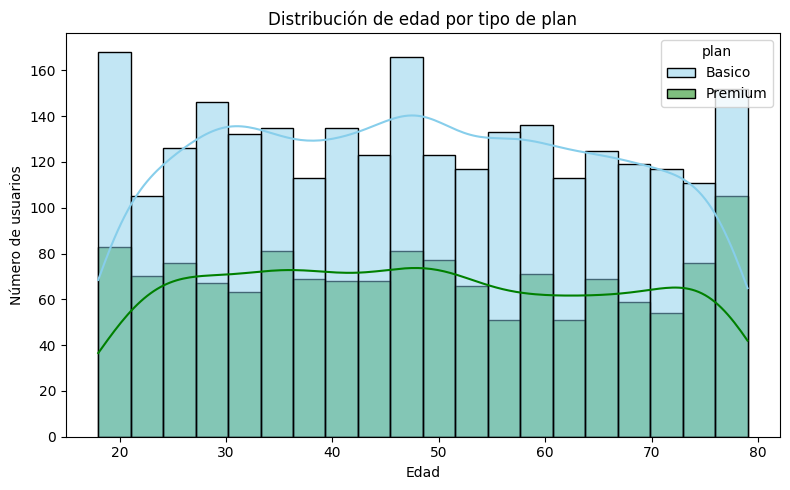

In [19]:
# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x="age",
    hue="plan",
    palette=["skyblue", "green"],
    bins=20,
    kde=True
)
plt.title("Distribución de edad por tipo de plan")
plt.xlabel("Edad")
plt.ylabel("Número de usuarios")
plt.tight_layout()
plt.show()

💡Insights: 
- Distribución ...
- **Insight — Edad**

La distribución de edades permite identificar los rangos de edad más frecuentes y comparar su presencia entre los planes Básico y Premium. La forma del histograma permitirá determinar si las edades se concentran en ciertos rangos o presentan una distribución más extendida.

**Conclusión específica:** pendiente de completar con lo observado en el gráfico.

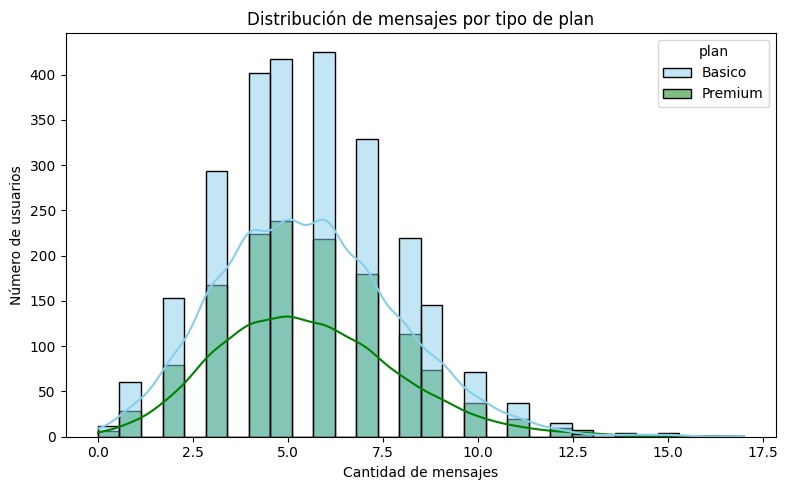

In [20]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x="cant_mensajes",
    hue="plan",
    palette=["skyblue", "green"],
    bins=30,
    kde=True
)
plt.title("Distribución de mensajes por tipo de plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Número de usuarios")
plt.tight_layout()
plt.show()

💡Insights: 
- ....
- **Insights — Distribución de mensajes**

- **Forma de la distribución:** presenta una asimetría hacia la derecha; la mayoría de los usuarios envía aproximadamente entre 3 y 8 mensajes, mientras que hay menos usuarios con cantidades elevadas, por encima de 10 mensajes.
- **Comparación por plan:** ambos planes muestran una concentración importante alrededor de 4 a 7 mensajes. El plan Básico presenta barras más altas, es decir, un mayor número absoluto de usuarios en esos intervalos. Esto no demuestra que sus usuarios envíen más mensajes individualmente, porque el número total de clientes de cada plan puede ser diferente.
- **Valores extremos:** se observa una cola hacia cantidades elevadas, con pocos usuarios que alcanzan aproximadamente 15 a 17 mensajes. Conviene revisar esos casos antes de clasificarlos como valores atípicos.
- **Conclusión comercial:** la concentración del uso en cantidades moderadas de mensajes puede ayudar a definir beneficios de mensajería adecuados para cada segmento. Para recomendar cambios específicos en los planes, primero debemos comparar el consumo por usuario y considerar el tamaño de cada grupo.

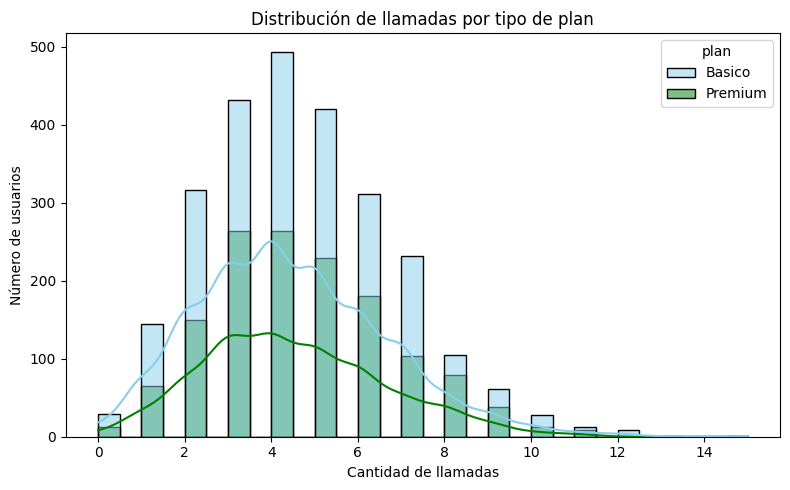

In [21]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x="cant_llamadas",
    hue="plan",
    palette=["skyblue", "green"],
    bins=30,
    kde=True
)
plt.title("Distribución de llamadas por tipo de plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Número de usuarios")
plt.tight_layout()
plt.show()

💡Insights: 
- Distribución ...
- **Insights — Distribución de llamadas**

- **Forma de la distribución:** presenta asimetría hacia la derecha. La mayoría de los usuarios realiza aproximadamente entre 2 y 7 llamadas, mientras que una proporción menor realiza más de 8.
- **Comparación por plan:** el plan Básico presenta un mayor número absoluto de usuarios en los intervalos principales, especialmente entre 3 y 5 llamadas. El plan Premium muestra una forma de distribución similar, aunque con barras más bajas. Esta diferencia puede estar relacionada con el tamaño de cada grupo y no demuestra, por sí sola, un mayor consumo individual.
- **Valores extremos:** se observa una cola con pocos usuarios que realizan alrededor de 10 a 15 llamadas. Estos casos pueden revisarse mediante métodos estadísticos, como el rango intercuartílico (IQR), antes de considerarlos valores atípicos.
- **Conclusión comercial:** la concentración del uso en cantidades moderadas de llamadas puede servir como referencia para evaluar las necesidades de comunicación de los clientes. Para comparar el consumo real entre planes, conviene analizar también los minutos utilizados por usuario y el tamaño de cada segmento.

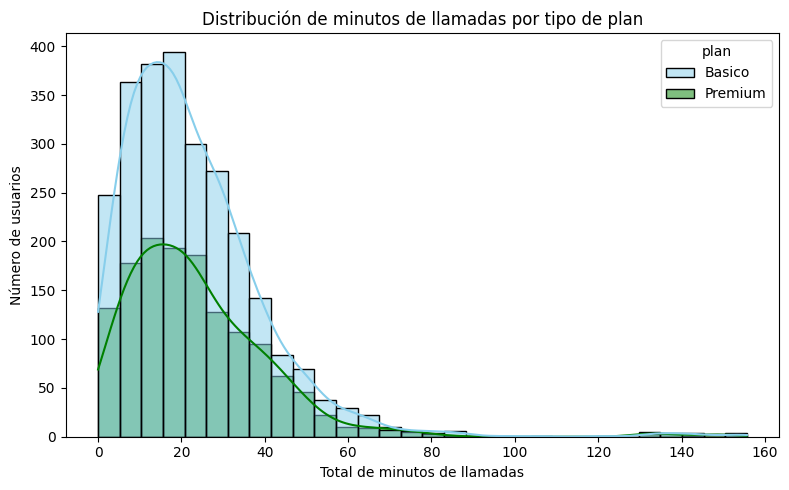

In [22]:
# Histograma para visualizar el total de minutos de llamadas
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x="cant_minutos_llamada",
    hue="plan",
    palette=["skyblue", "green"],
    bins=30,
    kde=True
)
plt.title("Distribución de minutos de llamadas por tipo de plan")
plt.xlabel("Total de minutos de llamadas")
plt.ylabel("Número de usuarios")
plt.tight_layout()
plt.show()

💡Insights: 
- ...
- **Insights — Distribución de minutos de llamadas**

- **Forma de la distribución:** presenta una asimetría hacia la derecha. La mayoría de los usuarios acumula aproximadamente entre 5 y 35 minutos de llamadas, mientras que pocos usuarios registran consumos superiores a 60 minutos.
- **Comparación por plan:** el plan Básico presenta más usuarios en términos absolutos en los intervalos de mayor concentración. El plan Premium muestra un patrón de distribución parecido, pero con menos observaciones. Para determinar qué plan tiene mayor consumo por usuario, es necesario comparar las estadísticas de ambos grupos y considerar su tamaño.
- **Valores extremos:** se observan algunos registros por encima de 100 minutos, incluso cercanos a 150 minutos. Conviene revisarlos con el método IQR para determinar si son valores atípicos; por sí solos, no indican errores ni comportamientos fraudulentos.
- **Conclusión comercial:** la concentración del consumo en intervalos moderados puede ayudar a identificar el uso habitual del servicio. Se recomienda comparar los minutos consumidos con los incluidos en cada plan para detectar clientes que podrían beneficiarse de una oferta diferente o de paquetes adicionales.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

In [24]:
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

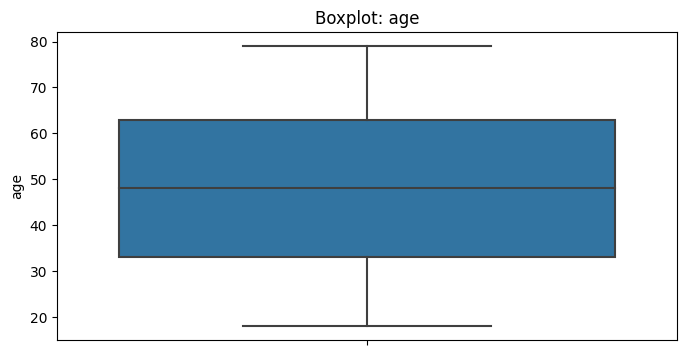

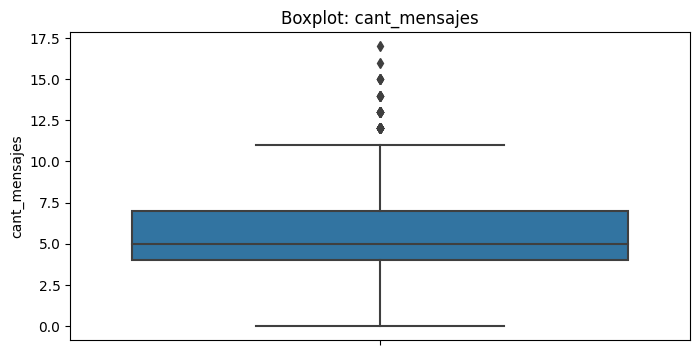

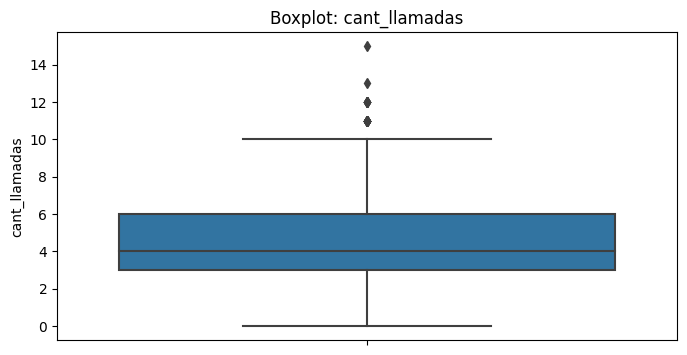

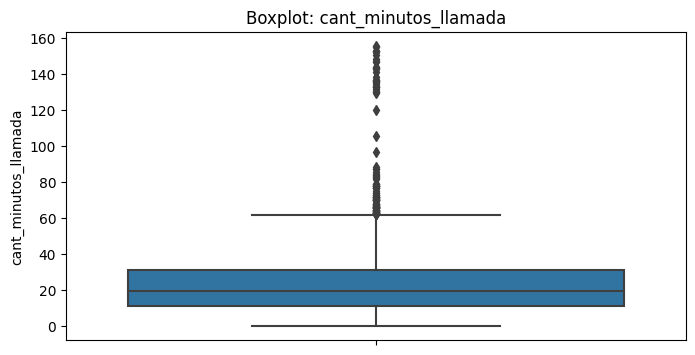

In [25]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, y=col)
    plt.title(f'Boxplot: {col}')
    plt.ylabel(col)
    plt.show()

💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...
- ### Insights: Identificación de outliers

- **age:** No se observan outliers. Las edades se distribuyen aproximadamente entre 18 y 79 años y no aparecen puntos fuera de los bigotes. Los valores parecen plausibles para la población de clientes.

- **cant_mensajes:** Sí se observan outliers superiores, aproximadamente entre 12 y 17 mensajes. La mayoría de los usuarios se concentra entre 4 y 7 mensajes. Recomiendo revisar estos valores, aunque podrían representar un uso legítimo del servicio.

- **cant_llamadas:** Sí se observan outliers superiores, aproximadamente entre 11 y 15 llamadas. La mayoría de los usuarios registra entre 3 y 6 llamadas. Estos valores pueden corresponder a clientes con mayor actividad y conviene validarlos antes de tomar decisiones.

- **cant_minutos_llamada:** Se observan numerosos outliers superiores, con registros que alcanzan aproximadamente 150–160 minutos. La mayoría de los usuarios se concentra en valores inferiores a 40 minutos. Es recomendable investigar estos registros para determinar si representan un consumo elevado real o posibles inconsistencias en los datos.

In [26]:
# Identificar outliers mediante el método IQR

for col in columnas_numericas:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = user_profile[
        (user_profile[col] < limite_inferior) |
        (user_profile[col] > limite_superior)
    ]

    print(f"\nVariable: {col}")
    print("Límite inferior:", limite_inferior)
    print("Límite superior:", limite_superior)
    print("Cantidad de outliers:", len(outliers))


Variable: age
Límite inferior: -12.0
Límite superior: 108.0
Cantidad de outliers: 0

Variable: cant_mensajes
Límite inferior: -0.5
Límite superior: 11.5
Cantidad de outliers: 46

Variable: cant_llamadas
Límite inferior: -1.5
Límite superior: 10.5
Cantidad de outliers: 30

Variable: cant_minutos_llamada
Límite inferior: -19.322500000000005
Límite superior: 61.8575
Cantidad de outliers: 109


In [27]:
# Revisar los límites superiores y el máximo de cada variable

display(user_profile[columnas_numericas].describe())

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?
- ### Insights: Decisión sobre valores atípicos

- **cant_mensajes — Mantener:** se detectaron 46 valores atípicos por encima del límite superior de 11.5 mensajes. Estos registros pueden representar clientes con mayor actividad de mensajería. Se recomienda conservarlos mientras no se identifiquen errores de captura.

- **cant_llamadas — Mantener:** se identificaron 30 valores atípicos por encima del límite superior de 10.5 llamadas. Estos valores podrían reflejar un uso intensivo del servicio, por lo que conviene conservarlos y analizarlos como posibles patrones de consumo elevado.

- **cant_minutos_llamada — Mantener temporalmente y revisar:** se detectaron 109 valores atípicos por encima del límite superior aproximado de 61.88 minutos. Debido a que algunos registros alcanzan valores considerablemente superiores al rango habitual, se recomienda verificar su plausibilidad antes de decidir si deben corregirse o excluirse.

**Conclusión:** los outliers estadísticos no son necesariamente errores. Se conservarán durante el análisis inicial para evitar perder información relevante sobre el comportamiento de los clientes. Cualquier eliminación o corrección deberá justificarse con evidencia adicional.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [33]:
import numpy as np

In [34]:
# Crear columna grupo_uso

user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) &
    (user_profile['cant_mensajes'] < 5),
    'Bajo uso',
    np.where(
        (user_profile['cant_llamadas'] < 10) &
        (user_profile['cant_mensajes'] < 10),
        'Uso medio',
        'Alto uso'
    )
)

In [31]:
print(user_profile['grupo_uso'].value_counts())
print(user_profile['grupo_uso'].value_counts(normalize=True) * 100)

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64
Uso medio    73.575
Bajo uso     19.450
Alto uso      6.975
Name: grupo_uso, dtype: float64


In [ ]:
### Insights: Segmentación de clientes por uso

- **Uso medio:** representa el 73.575 % de los clientes (2,943 usuarios). Es el segmento predominante, lo que indica que la mayoría cumple las condiciones intermedias de llamadas y mensajes definidas para este análisis.
- **Bajo uso:** representa el 19.45 % (778 usuarios). Estos clientes registran menos de 5 llamadas y menos de 5 mensajes, por lo que podrían ser candidatos para campañas de activación y mayor utilización de los servicios.
- **Alto uso:** representa el 6.975 % (279 usuarios). Son los clientes que no cumplen las condiciones de los otros dos segmentos. Conviene estudiar su consumo para evaluar si sus necesidades están cubiertas por el plan contratado.

**Conclusión comercial:** ConnectaTel podría diseñar estrategias diferenciadas: incentivar el uso entre los clientes de bajo consumo, mantener la satisfacción del segmento medio y evaluar posibles necesidades adicionales entre los clientes de alto uso.

**Nota metodológica:** los segmentos se definieron mediante umbrales de llamadas y mensajes. La clasificación no demuestra por sí sola que un cliente necesite cambiar de plan; esa decisión requiere comparar su consumo con los beneficios incluidos en su plan actual.

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [35]:
# Crear columna grupo_edad

user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30,
    'Joven',
    np.where(
        user_profile['age'] < 60,
        'Adulto',
        'Adulto Mayor'
    )
)

In [36]:
# Verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

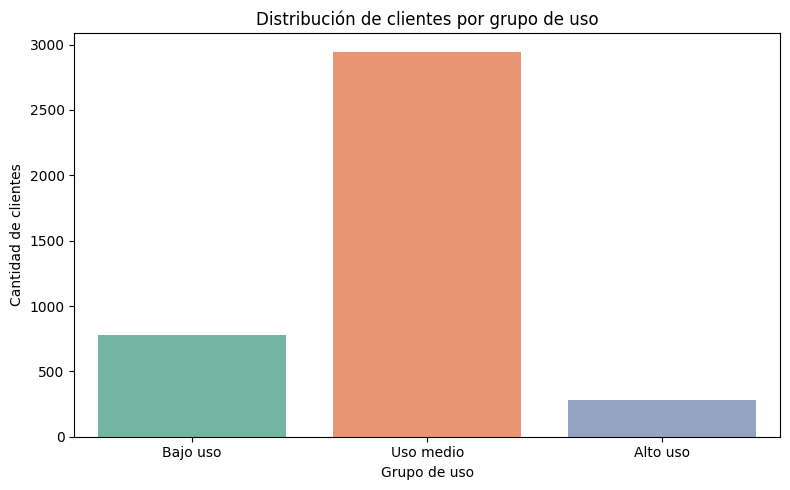

In [37]:
# Visualización de los segmentos por uso

plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_uso',
    palette='Set2',
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)

plt.title('Distribución de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()

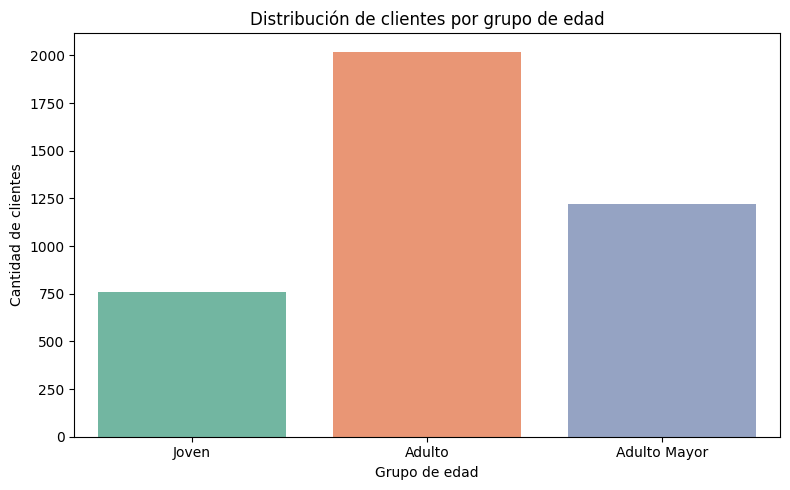

In [38]:
# Visualización de los segmentos por edad

plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_edad',
    palette='Set2',
    order=['Joven', 'Adulto', 'Adulto Mayor']
)

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

# Análisis ejecutivo

## ⚠️ Problemas detectados en los datos

Durante la exploración se identificaron valores faltantes e inconsistencias que requerían atención antes de realizar el análisis:

- **Dataset `users`:** se encontraron 469 valores faltantes en `city` (11.725 %) y 3,534 en `churn_date` (88.35 %). En `city`, se reemplazó el valor centinela `?` por valores nulos. Se recomienda conservar los registros sin ciudad para no perder información de clientes y evaluar `churn_date` según su significado; la ausencia de fecha de cancelación puede ser válida para clientes que siguen activos.
- **Dataset `usage`:** se encontraron 50 fechas faltantes (0.125 %), 22,076 duraciones faltantes (55.19 %) y 17,896 longitudes faltantes (44.74 %). La ausencia de `duration` está asociada principalmente a los registros de mensajes, mientras que la ausencia de `length` está asociada principalmente a los registros de llamadas. Esta relación es consistente con la estructura de los tipos de actividad y debe interpretarse considerando que ambas variables no aplican a todos los registros.
- **Valores inválidos:** se detectó el valor centinela `-999` en `age`, que fue sustituido por la mediana, y se identificó `?` en `city`, que se convirtió en valor nulo. Las fechas posteriores al cierre de 2024 se marcaron como nulas para evitar utilizarlas como fechas válidas del periodo analizado.
- **Valores atípicos:** se identificaron posibles outliers en el número de mensajes, llamadas y minutos de llamadas. Se decidió conservarlos inicialmente, ya que pueden representar consumos reales y no necesariamente errores de captura.

## 🔎 Segmentos por edad

Se crearon tres grupos: `Joven` (menores de 30 años), `Adulto` (de 30 a 59 años) y `Adulto Mayor` (60 años o más).

Esta segmentación permite comparar el comportamiento de consumo entre grupos etarios. Para determinar cuál concentra más clientes y si existen diferencias en llamadas y mensajes, es necesario revisar los conteos y las estadísticas por grupo obtenidos en el notebook.

## 📊 Segmentos por nivel de uso

Se clasificaron los clientes en tres grupos según sus llamadas y mensajes registrados:

- **Uso medio:** 2,943 clientes (73.575 %).
- **Bajo uso:** 778 clientes (19.45 %).
- **Alto uso:** 279 clientes (6.975 %).

El segmento de uso medio es el predominante. El grupo de bajo uso podría ser relevante para campañas de activación, mientras que los clientes de alto uso podrían requerir una evaluación de sus necesidades y de los beneficios incluidos en sus planes. Estas oportunidades deben validarse comparando el consumo con las condiciones comerciales de cada plan.

## ➡️ ¿Qué sugieren estos resultados?

Los datos permiten identificar diferencias en el comportamiento de uso y posibles oportunidades de segmentación comercial. Sin embargo, para determinar qué segmentos son más rentables o tienen mayor riesgo de cancelación, será necesario analizar también el plan contratado, los ingresos generados y la información de cancelación disponible.

## 💡 Recomendaciones

1. **Activación de clientes de bajo uso:** analizar las causas del consumo reducido y probar campañas de comunicación o incentivos para fomentar el uso de los servicios.
2. **Optimización de planes:** comparar el consumo real de llamadas y mensajes con los beneficios incluidos en los planes Básico y Premium para identificar oportunidades de ajuste.
3. **Atención a usuarios de alto consumo:** estudiar los registros extremos y evaluar si los beneficios actuales cubren adecuadamente sus necesidades.
4. **Mejora de la calidad de datos:** documentar las reglas aplicadas a valores faltantes, centinelas y fechas inválidas para garantizar que el análisis sea reproducible.
5. **Validación de resultados:** comparar los segmentos por edad, plan y nivel de uso antes de implementar campañas, evitando asumir que una categoría demográfica determina por sí sola las necesidades de un cliente.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

In [ ]:
# Proyecto 6: Análisis de una empresa de telecomunicaciones

## Descripción

Este proyecto analiza el comportamiento de los clientes de ConnectaTel, una empresa de telecomunicaciones con operaciones en México y Colombia. El objetivo es identificar patrones de uso de llamadas y mensajes, detectar valores atípicos y segmentar clientes para proponer oportunidades de mejora comercial.

## Objetivos

- Explorar y limpiar las fuentes de datos.
- Validar tipos de datos, valores faltantes e inconsistencias.
- Calcular estadísticas descriptivas del consumo.
- Visualizar distribuciones e identificar posibles valores atípicos.
- Segmentar clientes por nivel de uso y edad.
- Proponer recomendaciones comerciales basadas en los resultados.

## Datasets

- `plans.csv`: información de los planes y sus tarifas.
- `users_latam.csv`: información demográfica y contractual de los clientes.
- `usage.csv`: registros de llamadas y mensajes.

Los archivos de datos deben estar disponibles en las rutas que utiliza el notebook o adaptarse a la ubicación correspondiente.

## Herramientas

- Python
- pandas
- NumPy
- Seaborn
- Matplotlib
- Jupyter Notebook

## Etapas del análisis

1. Carga y exploración de los datasets.
2. Identificación de valores faltantes, centinelas e inconsistencias.
3. Limpieza y estandarización de datos.
4. Estadísticas descriptivas por usuario.
5. Visualización de distribuciones y detección de valores atípicos.
6. Segmentación por uso y edad.
7. Elaboración de conclusiones y recomendaciones comerciales.

## Cómo ejecutar el proyecto

1. Descarga o clona este repositorio.
2. Instala las bibliotecas necesarias: pandas, NumPy, Seaborn y Matplotlib.
3. Coloca los datasets en la carpeta esperada por el notebook o actualiza las rutas de lectura.
4. Abre el archivo `.ipynb` en Jupyter Notebook o Google Colab.
5. Ejecuta las celdas en orden y revisa los resultados.

## Resultados

El análisis busca identificar diferencias de consumo entre segmentos de clientes, documentar problemas de calidad de datos y generar recomendaciones para optimizar los planes y mejorar la experiencia del usuario.